# 01 · Inventory and three-level manifest

**What this notebook does.** It builds the sample manifest on three separate levels, because GSE298774 does
**not** map one GEO sample to one patient:

| Level | Meaning | File |
|---|---|---|
| Capture area (GSM) | one Visium capture area = one GEO sample = one sequencing library; 1–3 patients' tissue pieces were placed on it | `manifests/capture_areas.csv` |
| Tissue section / patient | one patient's tissue piece on a capture area; patient B38 has two pieces on two capture areas | `manifests/tissue_sections.csv` |
| Spot | one 55 µm capture spot with its barcode, coordinates and (later) QC | `manifests/spots.csv.gz` |

It also loads the count matrix of every usable section, keeps only that section's in-tissue spots, and saves one
`.h5ad` file per section to `data/GSE298774/processed/` (not committed) for the next notebooks.

**What the old notebook did wrong, and what changes here.**
* The old notebook labelled every spot "melanoma" because every GEO title contains the words *"Nevus and melanoma"*.
  Here **no pathology label is assigned** to sections or spots: GEO contains none at spot level
  (`region_label = "not available"`).
* The old notebook treated one GSM as one patient. Here patients come from the per-patient file names and
  Supplementary Table S1.
* Barcodes repeat on every capture area, so the spot key is `spot_uid = "<GSM>:<barcode>"`.

| | |
|---|---|
| **Inputs** | `data/GSE298774/raw/*.gz`, series matrix, `manifests/inventory/inventory_summary.csv`, Supplementary Table S1 |
| **Outputs** | the three manifests above, `manifests/skipped_samples.csv`, `manifests/geo_title_check.csv`, `manifests/load_report.csv`, `manifests/barcode_overlap_check.csv`, `figures/01_manifest/*.png`, `manifests/reconciliation_spatial_reasoning.csv`, processed `.h5ad` files |

In [1]:
# --- Setup: make src/ importable, load helpers, define all paths -------------
import sys
from pathlib import Path
REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacemel_io as sio
import spacemel_plots as splot

P = sio.get_paths()
sio.ensure_output_dirs(P)
FIG = P["figures"] / "01_manifest"
FIG.mkdir(parents=True, exist_ok=True)
MAN = P["manifests"]
pd.set_option("display.max_columns", 60, "display.width", 220, "display.max_colwidth", 80)
print("repo      :", P["repo"])
print("raw data  :", P["raw"])
print("figures ->:", FIG)
print("manifests:", MAN)

repo      : C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval
raw data  : C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\data\GSE298774\raw
figures ->: C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\figures\01_manifest
manifests: C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\manifests


## 1.1 · Files per section

Re-uses the file discovery from notebook 00.

In [2]:
files = sio.discover_files(P["raw"])
fbs = sio.files_by_section(files)
inventory = pd.read_csv(MAN / "inventory" / "inventory_summary.csv")
sections = sorted(fbs)
print(f"{len(sections)} sections on {len({g for g, _ in sections})} GSMs")
sections

19 sections on 11 GSMs


[('GSM9022963', 'A17'),
 ('GSM9022963', 'A2'),
 ('GSM9022964', 'A7'),
 ('GSM9022965', 'A21'),
 ('GSM9022966', 'A16'),
 ('GSM9022966', 'A23'),
 ('GSM9022967', 'A22'),
 ('GSM9022967', 'A24'),
 ('GSM9022968', 'A34'),
 ('GSM9022969', 'B1'),
 ('GSM9022969', 'B38ex'),
 ('GSM9022970', 'B4'),
 ('GSM9022971', 'B13'),
 ('GSM9022971', 'B8'),
 ('GSM9022972', 'B14'),
 ('GSM9022972', 'B15'),
 ('GSM9022972', 'B38_2'),
 ('GSM9022973', 'D20'),
 ('GSM9022973', 'D3')]

## 1.2 · What GEO says about each sample

The series matrix holds the title and protocol text of every GSM. The titles list the patients on each slide
(e.g. *"Nevus and melanoma in a single slide of patient A22 and A24"*). This cell compares those patient lists
with the section tokens in the file names. Note the one known naming difference: the file token `B38_2` is written
`B38.2` in GEO titles and in the paper.

The title wording "Nevus and melanoma" describes the **lesions on the slide**; it says nothing about which spots
are nevus and which are melanoma, so it is not used as a label.

In [3]:
series_path = P["data"] / "GSE298774_series_matrix.txt.gz"
geo = sio.parse_series_matrix(series_path)
rows = []
for gsm, title in geo["title"].items():
    in_title = sio.patients_in_geo_title(title)
    in_files = sorted(sio.section_label(s) for g, s in sections if g == gsm)
    rows.append({"gsm": gsm, "title": title, "patients_in_title": ";".join(sorted(in_title)),
                 "sections_in_files": ";".join(in_files), "match": sorted(in_title) == in_files})
title_check = pd.DataFrame(rows)
title_check.to_csv(MAN / "geo_title_check.csv", index=False)
title_check

,gsm,title,patients_in_title,sections_in_files,match
0,GSM9022963,Nevus and melanoma in a single slide of patient A2 and A17,A17;A2,A17;A2,True
1,GSM9022964,Nevus and melanoma in a single slide of patient A7,A7,A7,True
2,GSM9022965,Nevus and melanoma in a single slide of patient A21,A21,A21,True
3,GSM9022966,Nevus and melanoma in a single slide of patient A16 and A23,A16;A23,A16;A23,True
4,GSM9022967,Nevus and melanoma in a single slide of patient A22 and A24,A22;A24,A22;A24,True
5,GSM9022968,Nevus and melanoma in a single slide of patient A34,A34,A34,True
6,GSM9022969,Nevus and melanoma in a single slide of patient B1 and B38ex,B1;B38ex,B1;B38ex,True
7,GSM9022970,Nevus and melanoma in a single slide of patient B4,B4,B4,True
8,GSM9022971,Nevus and melanoma in a single slide of patient B8 and B13,B13;B8,B13;B8,True
9,GSM9022972,"Nevus and melanoma in a single slide of patient B14, B15 and B38.2",B14;B15;B38.2,B14;B15;B38.2,True


In [4]:
# All descriptive GEO fields, as text, for the record (source / characteristics / description / protocols).
text_cols = [c for c in geo.columns if c.split("_")[0] in
             ("source", "characteristics", "description", "data", "extract", "label", "treatment", "growth")]
geo[text_cols].T

gsm,GSM9022963,GSM9022964,GSM9022965,GSM9022966,GSM9022967,GSM9022968,GSM9022969,GSM9022970,GSM9022971,GSM9022972,GSM9022973
source_name_ch1,Skin,Skin,Skin,Skin,Skin,Skin,Skin,Skin,Skin,Skin,Skin
characteristics_ch1,tissue: Skin,tissue: Skin,tissue: Skin,tissue: Skin,tissue: Skin,tissue: Skin,tissue: Skin,tissue: Skin,tissue: Skin,tissue: Skin,tissue: Skin
extract_protocol_ch1_0,According to manufacturer's protocol,According to manufacturer's protocol,According to manufacturer's protocol,According to manufacturer's protocol,According to manufacturer's protocol,According to manufacturer's protocol,According to manufacturer's protocol,According to manufacturer's protocol,According to manufacturer's protocol,According to manufacturer's protocol,According to manufacturer's protocol
extract_protocol_ch1_1,The sequencing libraries were further prepared as per manufacturer’s instruc...,The sequencing libraries were further prepared as per manufacturer’s instruc...,The sequencing libraries were further prepared as per manufacturer’s instruc...,The sequencing libraries were further prepared as per manufacturer’s instruc...,The sequencing libraries were further prepared as per manufacturer’s instruc...,The sequencing libraries were further prepared as per manufacturer’s instruc...,The sequencing libraries were further prepared as per manufacturer’s instruc...,The sequencing libraries were further prepared as per manufacturer’s instruc...,The sequencing libraries were further prepared as per manufacturer’s instruc...,The sequencing libraries were further prepared as per manufacturer’s instruc...,The sequencing libraries were further prepared as per manufacturer’s instruc...
description_0,"Library name: A2, A17",Library name: A7,Library name: A21,"Library name: A16, A23","Library name: A22, A24",Library name: A34,"Library name: B1, B38ex",Library name: B4,"Library name: B8, B13","Library name: B14, B15, B38.2","Library name: D3, D20"
description_1,FFPE Spatial transcriptomics,FFPE Spatial transcriptomics,FFPE Spatial transcriptomics,FFPE Spatial transcriptomics,FFPE Spatial transcriptomics,FFPE Spatial transcriptomics,FFPE Spatial transcriptomics,FFPE Spatial transcriptomics,FFPE Spatial transcriptomics,FFPE Spatial transcriptomics,FFPE Spatial transcriptomics
data_processing_0,Raw sequencing data was processed using 10x SpaceRanger (v2.1.1) based on a ...,Raw sequencing data was processed using 10x SpaceRanger (v2.1.1) based on a ...,Raw sequencing data was processed using 10x SpaceRanger (v2.1.1) based on a ...,Raw sequencing data was processed using 10x SpaceRanger (v2.1.1) based on a ...,Raw sequencing data was processed using 10x SpaceRanger (v2.1.1) based on a ...,Raw sequencing data was processed using 10x SpaceRanger (v2.1.1) based on a ...,Raw sequencing data was processed using 10x SpaceRanger (v2.1.1) based on a ...,Raw sequencing data was processed using 10x SpaceRanger (v2.1.1) based on a ...,Raw sequencing data was processed using 10x SpaceRanger (v2.1.1) based on a ...,Raw sequencing data was processed using 10x SpaceRanger (v2.1.1) based on a ...,Raw sequencing data was processed using 10x SpaceRanger (v2.1.1) based on a ...
data_processing_1,Assembly: hg38,Assembly: hg38,Assembly: hg38,Assembly: hg38,Assembly: hg38,Assembly: hg38,Assembly: hg38,Assembly: hg38,Assembly: hg38,Assembly: hg38,Assembly: hg38
data_processing_2,Supplementary files format and content: aligned_fiducials.jpg = aligned fidu...,Supplementary files format and content: aligned_fiducials.jpg = aligned fidu...,Supplementary files format and content: aligned_fiducials.jpg = aligned fidu...,Supplementary files format and content: aligned_fiducials.jpg = aligned fidu...,Supplementary files format and content: aligned_fiducials.jpg = aligned fidu...,Supplementary files format and content: aligned_fiducials.jpg = aligned fidu...,Supplementary files format and content: aligned_fiducials.jpg = aligned fidu...,Supplementary files format and content: aligned_fidu

## 1.3 · Capture-area level

For every GSM this table records the array size, the images and their pixel sizes, and the scale factors.

**How micrometres per pixel are obtained.** `tissue_positions.csv` gives each spot's position in *full-resolution*
pixels, i.e. pixels of the original microscope image, which is **not** in GEO. On the Visium grid, neighbouring spots
in the same row are exactly 100 µm apart. The median pixel distance between such neighbours therefore gives
µm per full-resolution pixel (`um_per_fullres_px`). Each distributed image is a scaled copy:
image pixel = full-res pixel × scale factor (`tissue_hires_scalef`, `tissue_lowres_scalef`,
`regist_target_img_scalef` for `aligned_fiducials.jpg`). Hence µm per image pixel = `um_per_fullres_px / scalef`.

`spot_diameter_fullres_um` converts Space Ranger's `spot_diameter_fullres` to µm with the grid scale, so it can be
compared with the physical 55 µm. `grid_rel_iqr` is the spread of the neighbour distances (small = regular grid).

In [5]:
ca_rows = []
for gsm in sorted({g for g, _ in sections}):
    secs = [s for g, s in sections if g == gsm]
    sfs = [sio.load_scalefactors(fbs[(gsm, s)]["scalefactors"]) for s in secs]
    pos = sio.load_positions(fbs[(gsm, secs[0])]["positions"])
    um, n_pairs, spread = sio.grid_um_per_px(pos)
    sf = sfs[0]
    inv = inventory[inventory.gsm == gsm].iloc[0]
    ca_rows.append({
        "gsm": gsm,
        "sections": ";".join(sio.section_label(s) for s in secs),
        "n_sections": len(secs),
        "array_positions": len(pos),
        "array_size": sio.ARRAY_SIZE_BY_N_SPOTS.get(len(pos), "unknown"),
        "scalefactors_identical_across_sections": all(s == sf for s in sfs),
        "um_per_fullres_px": round(um, 4), "grid_pairs": n_pairs, "grid_rel_iqr": round(spread, 4),
        "tissue_hires_scalef": sf["tissue_hires_scalef"],
        "tissue_lowres_scalef": sf["tissue_lowres_scalef"],
        "regist_target_img_scalef": sf.get("regist_target_img_scalef"),
        "hires_wh": inv["hires_wh"], "lowres_wh": inv["lowres_wh"], "fiducials_wh": inv["fiducials_wh"],
        "um_per_hires_px": round(um / sf["tissue_hires_scalef"], 2),
        "um_per_lowres_px": round(um / sf["tissue_lowres_scalef"], 2),
        "um_per_fiducials_px": round(um / sf["regist_target_img_scalef"], 2) if sf.get("regist_target_img_scalef") else None,
        "spot55um_in_hires_px": round(sio.SPOT_DIAMETER_UM / (um / sf["tissue_hires_scalef"]), 1),
        "spot_diameter_fullres": sf["spot_diameter_fullres"],
        "spot_diameter_fullres_um": round(sf["spot_diameter_fullres"] * um, 1),
    })
capture_areas = pd.DataFrame(ca_rows)
capture_areas.to_csv(MAN / "capture_areas.csv", index=False)
capture_areas

,gsm,sections,n_sections,array_positions,array_size,scalefactors_identical_across_sections,um_per_fullres_px,grid_pairs,grid_rel_iqr,tissue_hires_scalef,tissue_lowres_scalef,regist_target_img_scalef,hires_wh,lowres_wh,fiducials_wh,um_per_hires_px,um_per_lowres_px,um_per_fiducials_px,spot55um_in_hires_px,spot_diameter_fullres,spot_diameter_fullres_um
0,GSM9022963,A17;A2,2,14336,11 mm,True,0.3663,14208,0.0037,0.033015,0.009905,0.099046,"[2000, 1989]","[600, 597]","[3000, 3000]",11.09,36.98,3.70,5.0,163.630909,59.9
1,GSM9022964,A7,1,4992,6.5 mm,True,0.2198,4914,0.0000,0.042960,0.012888,0.128880,"[1677, 2000]","[503, 600]","[3000, 3000]",5.12,17.05,1.71,10.8,318.374339,70.0
2,GSM9022965,A21,1,4992,6.5 mm,True,0.2941,4914,0.0000,0.037701,0.011310,0.113103,"[2000, 1894]","[600, 568]","[3000, 3000]",7.80,26.00,2.60,7.1,237.919077,70.0
3,GSM9022966,A16;A23,2,14336,11 mm,True,0.3676,14208,0.0037,0.031214,0.009364,0.093643,"[2000, 1639]","[600, 492]","[3000, 3000]",11.78,39.26,3.93,4.7,163.447121,60.1
4,GSM9022967,A22;A24,2,14336,11 mm,True,0.3861,14208,0.0000,0.034264,0.010279,0.102793,"[2000, 1834]","[600, 550]","[3000, 3000]",11.27,37.56,3.76,4.9,155.369556,60.0
5,GSM9022968,A34,1,14336,11 mm,True,0.2825,14208,0.0028,0.031742,0.009523,0.095226,"[2000, 1391]","[600, 417]","[3000, 3000]",8.90,29.66,2.97,6.2,212.233402,60.0
6,GSM9022969,B1;B38ex,2,14336,11 mm,True,0.3236,14208,0.0032,0.037086,0.011126,0.111257,"[2000, 1934]","[600, 580]","[3000, 3000]",8.73,29.09,2.91,6.3,185.193732,59.9
7,GSM9022970,B4,1,14336,11 mm,True,0.3401,14208,0.0034,0.037506,0.011252,0.112518,"[1934, 2000]","[580, 600]","[3000, 3000]",9.07,30.23,3.02,6.1,176.223405,59.9
8,GSM9022971,B13;B8,2,14336,11 mm,True,0.2933,14208,0.0000,0.033342,0.010003,0.100027,"[1732, 2000]","[520, 600]","[3000, 3000]",8.80,29.32,2.93,6.3,204.605856,60.0
9,GSM9022972,B14;B15;B38.2,3,14336,11 mm,True,0.2941,14208,0.0000,0.034246,0.010274,0.102738,"[2000, 1778]","[600, 534]","[3000, 3000]",8.59,28.63,2.86,6.4,203.988624,60.0


## 1.4 · Skipped sections

Sections that are not used, with the reason. A2 is excluded by project decision: GEO has no `barcodes.tsv` for
it, so its matrix columns cannot be assigned to spots, and no recovery is attempted.
Any other section missing a required file is added automatically.

In [6]:
REQUIRED = ["positions", "scalefactors", "matrix", "barcodes", "features"]
skipped = []
for g, s in sections:
    missing = [k for k in REQUIRED if k not in fbs[(g, s)]]
    if s in sio.EXCLUDED_SECTIONS:
        skipped.append({"gsm": g, "section_id": s, "reason": sio.EXCLUDED_SECTIONS[s],
                        "missing_files": ";".join(missing)})
    elif missing:
        skipped.append({"gsm": g, "section_id": s, "reason": "required files missing",
                        "missing_files": ";".join(missing)})
skipped = pd.DataFrame(skipped, columns=["gsm", "section_id", "reason", "missing_files"])
skipped.to_csv(MAN / "skipped_samples.csv", index=False)
usable = [(g, s) for g, s in sections if s not in set(skipped.section_id)]
print(f"usable sections: {len(usable)}")
skipped

usable sections: 18


,gsm,section_id,reason,missing_files
0,GSM9022963,A2,"No barcodes.tsv file in GEO; its matrix has 13,916 columns that cannot be ma...",barcodes;features


## 1.5 · Load every usable section

For each section: read the positions, keep spots with `in_tissue == 1`, read the count matrix and keep exactly those
barcodes. On shared capture areas the matrix covers the whole array, so this step is what separates patients.
Raw counts are stored unchanged (`layers["counts"]`). Coordinates are stored in full-resolution pixels and in µm.

The load report shows, per section, how many in-tissue spots were found in the matrix. A non-zero
`in_tissue_missing_from_matrix` means positions list a spot that has no column in the matrix.

*Run time / memory:* several matrices are ~200 MB compressed (whole 11 mm arrays); loading all sections can take
several minutes. Sections already processed are skipped; set `REBUILD = True` to redo them.

In [7]:
REBUILD = False
reports = []
for g, s in usable:
    out = sio.processed_path(P, g, s)
    rep = None
    if out.exists() and not REBUILD:
        try:
            rep = sio.read_processed(P, g, s).uns["load_report"]
        except Exception as e:          # incomplete file from an interrupted or failed save
            print(f"{g} {s}: existing file unusable ({type(e).__name__}) -> rebuilding")
    if rep is None:
        a, rep = sio.load_section(g, s, fbs[(g, s)])
        a.uns["load_report"] = rep
        tmp = out.with_suffix(".h5ad.part")
        a.write_h5ad(tmp, compression="gzip")
        tmp.replace(out)
    reports.append(dict(rep))
    print(f"{g} {s:6s}: {rep['spots_loaded']:5d} spots, {rep['n_genes_panel']} genes, matrix = {rep['matrix_scope']}")
load_report = pd.DataFrame(reports)
load_report.to_csv(MAN / "load_report.csv", index=False)
load_report

GSM9022963 A17   :  2274 spots, 37082 genes, matrix = whole capture area
GSM9022964 A7    :  2892 spots, 37082 genes, matrix = whole capture area
GSM9022965 A21   :  2260 spots, 18085 genes, matrix = this section only
GSM9022966 A16   :  5195 spots, 18085 genes, matrix = this section only
GSM9022966 A23   :  2782 spots, 18085 genes, matrix = this section only
GSM9022967 A22   :  4326 spots, 37082 genes, matrix = whole capture area
GSM9022967 A24   :  6165 spots, 37082 genes, matrix = whole capture area
GSM9022968 A34   :  4151 spots, 37082 genes, matrix = whole capture area
GSM9022969 B1    :  3952 spots, 37082 genes, matrix = whole capture area
GSM9022969 B38ex :  1861 spots, 37082 genes, matrix = whole capture area
GSM9022970 B4    :  6415 spots, 37082 genes, matrix = whole capture area
GSM9022971 B13   :  3614 spots, 37082 genes, matrix = whole capture area
GSM9022971 B8    :  5780 spots, 37082 genes, matrix = whole capture area
GSM9022972 B14   :  2206 spots, 37082 genes, matrix = 

,gsm,in_tissue,in_tissue_missing_from_matrix,matrix_barcodes,matrix_scope,n_genes_panel,positions_rows,section_id,spots_loaded,um_per_fullres_px
0,GSM9022963,2274,0,13887,whole capture area,37082,14336,A17,2274,0.366300
1,GSM9022964,2892,0,4985,whole capture area,37082,4992,A7,2892,0.219754
2,GSM9022965,2260,0,2260,this section only,18085,4992,A21,2260,0.294116
3,GSM9022966,5195,0,5195,this section only,18085,14336,A16,5195,0.367607
4,GSM9022966,2782,0,2782,this section only,18085,14336,A23,2782,0.367607
5,GSM9022967,4326,0,14336,whole capture area,37082,14336,A22,4326,0.386074
6,GSM9022967,6165,0,14335,whole capture area,37082,14336,A24,6165,0.386074
7,GSM9022968,4151,0,14203,whole capture area,37082,14336,A34,4151,0.282481
8,GSM9022969,3952,0,14328,whole capture area,37082,14336,B1,3952,0.323609
9,GSM9022969,1861,0,14328,whole capture area,37082,14336,B38ex,1861,0.323609


## 1.6 · Do sections on the same capture area overlap?

If two patients' sections shared a spot, that spot's RNA could not be attributed to either patient.
This cell counts the in-tissue barcodes shared by every pair of sections on the same GSM, and checks that
`spot_uid` is unique across the whole dataset.

In [8]:
from itertools import combinations
bc = {}
for g, s in usable:
    pos = sio.load_positions(fbs[(g, s)]["positions"])
    bc[(g, s)] = set(pos.index[pos.in_tissue == 1])
ov = []
for gsm in sorted({g for g, _ in usable}):
    secs = [s for g, s in usable if g == gsm]
    for s1, s2 in combinations(secs, 2):
        ov.append({"gsm": gsm, "section_1": s1, "section_2": s2,
                   "shared_in_tissue_barcodes": len(bc[(gsm, s1)] & bc[(gsm, s2)])})
overlap = pd.DataFrame(ov, columns=["gsm", "section_1", "section_2", "shared_in_tissue_barcodes"])
overlap.to_csv(MAN / "barcode_overlap_check.csv", index=False)
display(overlap)
all_uids = [f"{g}:{b}" for (g, s), bs in bc.items() for b in bs]
print("spot_uid unique across all usable sections:", len(all_uids) == len(set(all_uids)))

,gsm,section_1,section_2,shared_in_tissue_barcodes
0,GSM9022966,A16,A23,0
1,GSM9022967,A22,A24,0
2,GSM9022969,B1,B38ex,0
3,GSM9022971,B13,B8,0
4,GSM9022972,B14,B15,0
5,GSM9022972,B14,B38_2,0
6,GSM9022972,B15,B38_2,0
7,GSM9022973,D20,D3,0


spot_uid unique across all usable sections: True


## 1.7 · Tissue-section / patient level

One row per section found in GEO (including skipped ones), joined with Supplementary Table S1 through the patient ID
(column "Visium ID" in S1; the authors' script `RandomEffectsModel.md` joins on the same column).

`in_paper_S1C` marks the 18 individuals shown in Supplementary Fig. S1C/S1D; B38ex is not among them.

In [9]:
ts = pd.DataFrame([{"gsm": g, "section_id": s, "section_label": sio.section_label(s),
                    "patient_id": sio.patient_of(s)} for g, s in sections])
ts["shares_capture_area_with"] = ts.apply(
    lambda r: ";".join(x for x in ts.loc[ts.gsm == r.gsm, "section_label"] if x != r.section_label) or "none", axis=1)
ts["sections_of_same_patient"] = ts.groupby("patient_id")["section_label"].transform(lambda x: ";".join(x))
ts["in_paper_S1C"] = ts["section_label"].isin(sio.PAPER_S1C_SECTIONS)
ts["used_in_this_project"] = ~ts["section_id"].isin(skipped.section_id)
ts = ts.merge(load_report[["gsm", "section_id", "n_genes_panel", "matrix_scope", "in_tissue",
                           "in_tissue_missing_from_matrix", "spots_loaded"]],
              on=["gsm", "section_id"], how="left")
if P["supp_tables"].exists():
    s1 = sio.load_supp_table(P["supp_tables"], "S1").rename(columns={"Visium ID": "patient_id", "Patient#": "patient_number"})
    ts = ts.merge(s1, on="patient_id", how="left")
    print("patients in Table S1 :", s1.patient_id.nunique())
else:
    print("Supplementary Table S1 not found - clinical columns omitted:", P["supp_tables"])
print("sections in GEO      :", len(ts))
print("patients in GEO      :", ts.patient_id.nunique())
print("sections used        :", int(ts.used_in_this_project.sum()))
print("patients used        :", ts.loc[ts.used_in_this_project, "patient_id"].nunique())
ts.to_csv(MAN / "tissue_sections.csv", index=False)
ts

patients in Table S1 : 18
sections in GEO      : 19
patients in GEO      : 18
sections used        : 18
patients used        : 17


,gsm,section_id,section_label,patient_id,shares_capture_area_with,sections_of_same_patient,in_paper_S1C,used_in_this_project,n_genes_panel,matrix_scope,in_tissue,in_tissue_missing_from_matrix,spots_loaded,patient_number,Sex,Age at time of diagnosis,Anatomical location,Breslow thickness,Melanoma stage,Ulceration,WHO classification,PRAME staining (nevus/melanoma),P16 staining (nevus/melanoma),includes melanoma in situ component?,includes dermal nevus component?
0,GSM9022963,A17,A17,A17,A2,A17,True,True,37082.0,whole capture area,2274.0,0.0,2274.0,17,Female,36,"face, cheek",1.1 mm,"T2aN0M0, Stage IB",no,(I) Low CSD melanoma,-/+,Checkerboard/aberrant,yes,yes
1,GSM9022963,A2,A2,A2,A17,A2,True,False,NaN,NaN,NaN,NaN,NaN,2,Female,49,shoulder,0.4 mm,"T1aN0M0, Stage IA",no,(I) Low CSD melanoma,-/ ±,Checkerboard/aberrant,yes,yes
2,GSM9022964,A7,A7,A7,none,A7,True,True,37082.0,whole capture area,2892.0,0.0,2892.0,7,Female,31,lower back,0.9 mm,"T1bN0M0, Stage IA",no,(I) Low CSD melanoma,-/-,Checkerboard/aberrant,yes,yes
3,GSM9022965,A21,A21,A21,none,A21,True,True,18085.0,this section only,2260.0,0.0,2260.0,21,Female,40,lower back,1.3 mm,"T2aN0M0, Stage IB",no,(I) Low CSD melanoma,-/ ±,Checkerboard/aberrant,yes,yes
4,GSM9022966,A16,A16,A16,A23,A16,True,True,18085.0,this section only,5195.0,0.0,5195.0,16,Female,72,shoulder,1.2 mm,"T2aN0M0, Stage IB",no,(I) Low CSD melanoma,-/ ±,Checkerboard/aberrant,yes,yes
5,GSM9022966,A23,A23,A23,A16,A23,True,True,18085.0,this section only,2782.0,0.0,2782.0,23,Male,37,shoulder,0.9 mm,"T1bN0M0, Stage IA",no,(I) Low CSD melanoma,-/ ±,Checkerboard/aberrant,yes,yes
6,GSM9022967,A22,A22,A22,A24,A22,True,True,37082.0,whole capture area,4326.0,0.0,4326.0,22,Male,48,lower back,1.5 mm,"T2aN0M0, Stage IB",no,(I) Low CSD melanoma,-/ ±,Checkerboard/aberrant,yes,yes
7,GSM9022967,A24,A24,A24,A22,A24,True,True,37082.0,whole capture area,6165.0,0.0,6165.0,24,Male,71,upper arm,2.4 mm,"T3aN0M0, Stage IIA",no,(I) Low CSD melanoma,-/+,Checkerboard/aberrant,yes,yes
8,GSM9022968,A34,A34,A34,none,A34,True,True,37082.0,whole capture area,4151.0,0.0,4151.0,34,Female,17,"face, temporal",0.9 mm,"T1bN0M0, Stage IA",no,(I) Low CSD melanoma,-/ ±,Checkerboard/aberrant,yes,yes
9,GSM9022969,B1,B1,B1,B38ex,B1,True,True,37082.0,whole capture area,3952.0,0.0,3952.0,1,Male,48,mid back,3.1 mm,"T3aN0M0, Stage IIA",no,(I) Low CSD melanoma,-/ ±,Checkerboard/aberrant,yes,yes


## 1.8 · Spot level

One row per in-tissue spot of every usable section. Columns:
`spot_uid, gsm, section_id, patient_id, barcode, array_row, array_col, pxl_row_in_fullres, pxl_col_in_fullres,
x_um, y_um, hires_x, hires_y, region_label`. QC columns are added by notebook 02.
`region_label` is `"not available"`: GEO contains no nevus / melanoma / stroma annotation per spot.
Saved compressed (`spots.csv.gz`) to keep the repository small.

In [10]:
spot_frames = []
for g, s in usable:
    a = sio.read_processed(P, g, s)
    sf = a.uns["section_meta"]["scalefactors"]
    o = a.obs[["spot_uid", "gsm", "section_id", "patient_id", "barcode", "array_row", "array_col",
               "pxl_row_in_fullres", "pxl_col_in_fullres", "x_um", "y_um"]].copy()
    o["hires_x"], o["hires_y"] = sio.fullres_to_image(o.pxl_row_in_fullres, o.pxl_col_in_fullres, sf, "hires")
    o["region_label"] = "not available"
    spot_frames.append(o)
spots = pd.concat(spot_frames, ignore_index=True)
spots.to_csv(MAN / "spots.csv.gz", index=False, compression="gzip")
print(spots.shape)
spots.groupby(["gsm", "section_id"]).size().rename("n_spots").to_frame()

(61734, 14)


n_spots
gsm        section_id         
GSM9022963 A17            2274
GSM9022964 A7             2892
GSM9022965 A21            2260
GSM9022966 A16            5195
           A23            2782
GSM9022967 A22            4326
           A24            6165
GSM9022968 A34            4151
GSM9022969 B1             3952
           B38ex          1861
GSM9022970 B4             6415
GSM9022971 B13            3614
           B8             5780
GSM9022972 B14            2206
           B15            3171
           B38_2          2100
GSM9022973 D20            1089
           D3             1501

   ## 1.9 · Visual check: patients on shared capture areas

   One panel per capture area: the hires H&E image (faded so the spots stand out) with each section's in-tissue spots
   drawn as true-size (55 µm) circles, one colour per section. The dashed rectangle is the bounding box of all spot
   centres of the array (from `tissue_positions.csv`, which lists every array position): tissue outside it could not be
   measured. It runs through the centres of the outermost spots, so it is half a spot (27.5 µm) smaller than the
   physical capture area on each side.

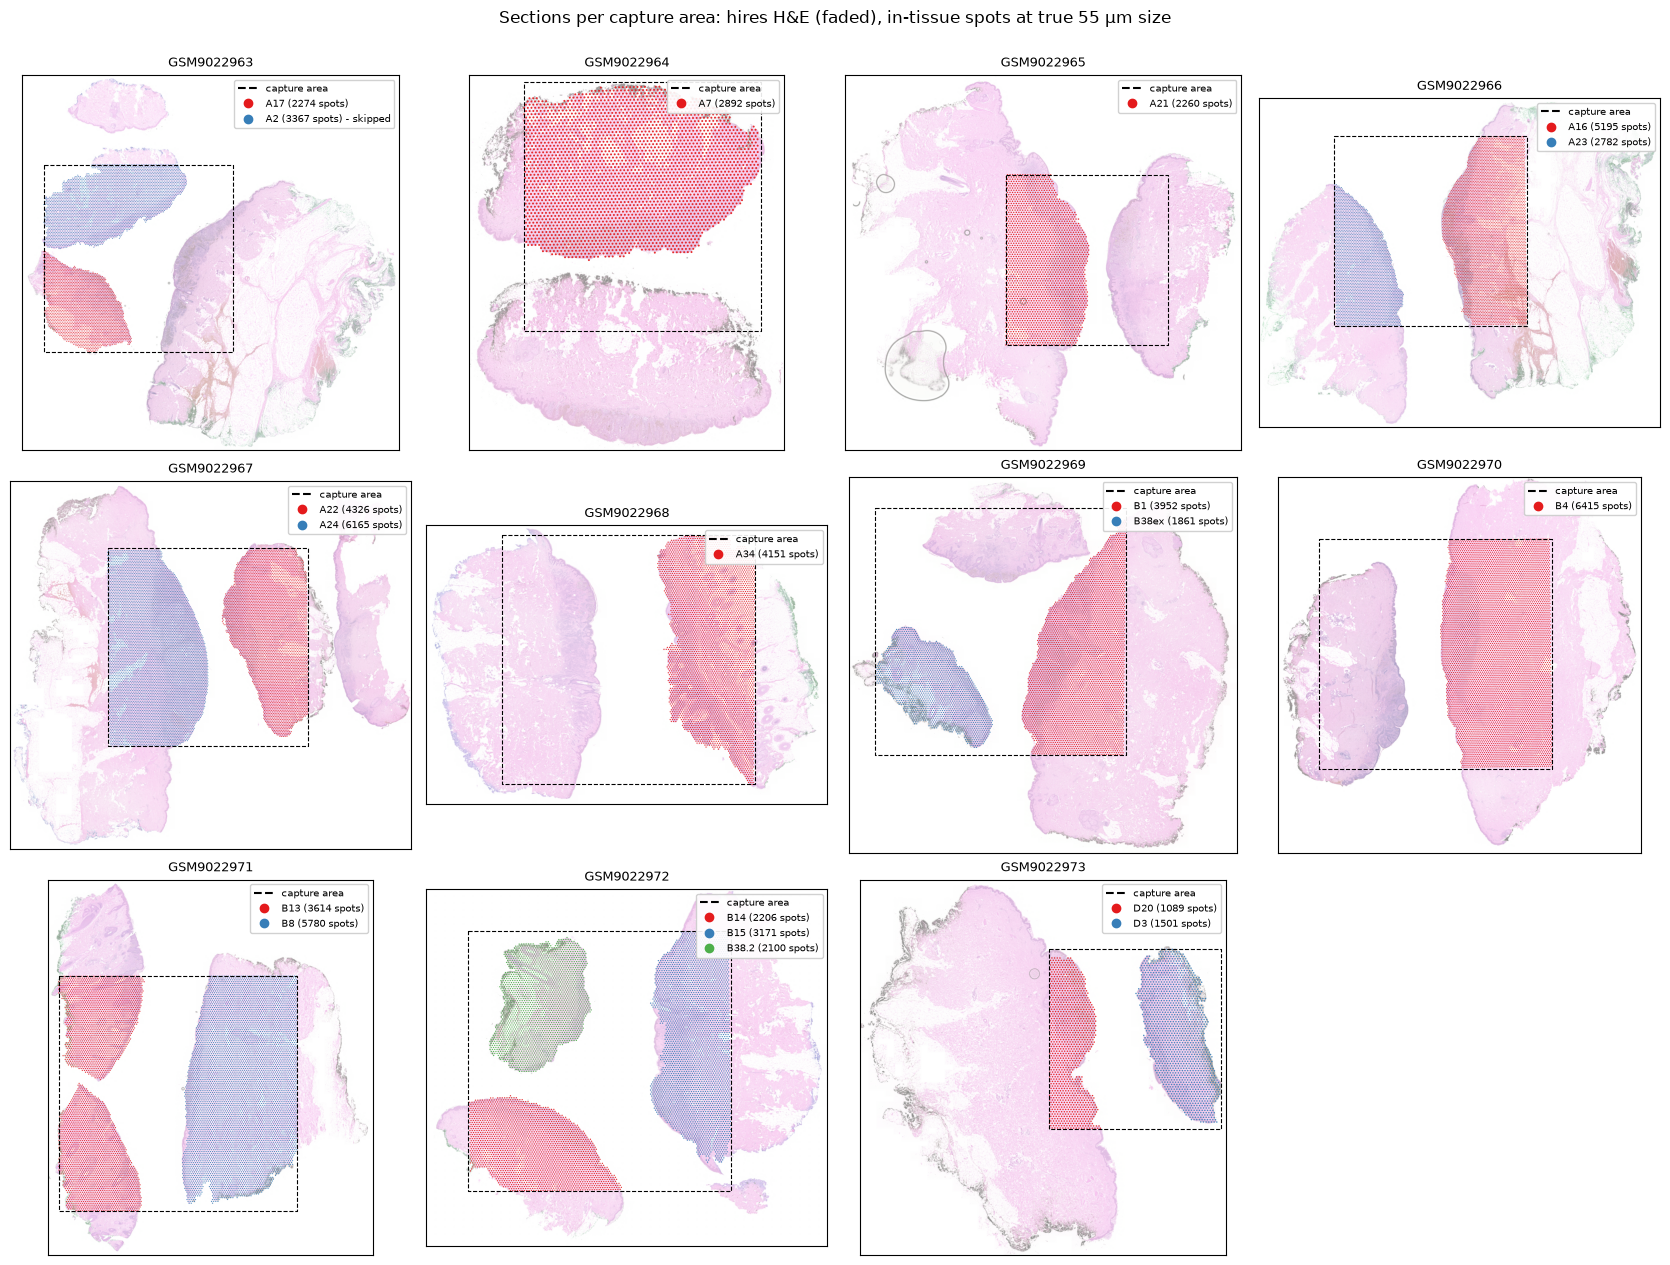

In [11]:
gsms = sorted({g for g, _ in sections})
fig, axes = splot.grid_axes(len(gsms), ncols=4, size=4.2)
colors = ["#e41a1c", "#377eb8", "#4daf4a"]          # strong colours, readable on H&E
for ax, gsm in zip(axes, gsms):
    secs = [s for g, s in sections if g == gsm]
    sf = sio.load_scalefactors(fbs[(gsm, secs[0])]["scalefactors"])
    img = sio.load_image(fbs[(gsm, secs[0])]["hires_image"])
    d_px = sio.SPOT_DIAMETER_UM / capture_areas.set_index("gsm").loc[gsm, "um_per_hires_px"]
    ax.imshow(img, alpha=0.45)                       # faded H&E so the spots stand out
    allpos = sio.load_positions(fbs[(gsm, secs[0])]["positions"])
    ax_x, ax_y = sio.fullres_to_image(allpos.pxl_row_in_fullres, allpos.pxl_col_in_fullres, sf, "hires")
    ax.plot([ax_x.min(), ax_x.max(), ax_x.max(), ax_x.min(), ax_x.min()],
            [ax_y.min(), ax_y.min(), ax_y.max(), ax_y.max(), ax_y.min()], "k--", lw=0.8)  # capture area outline
    handles = [plt.Line2D([], [], color="k", ls="--", label="capture area")]
    for i, s in enumerate(secs):
        pos = sio.load_positions(fbs[(gsm, s)]["positions"])
        pos = pos[pos.in_tissue == 1]
        x, y = sio.fullres_to_image(pos.pxl_row_in_fullres, pos.pxl_col_in_fullres, sf, "hires")
        splot.spot_circles(ax, x, y, d_px, color=colors[i], alpha=0.9)
        handles.append(plt.Line2D([], [], marker="o", ls="", color=colors[i],
                                  label=f"{sio.section_label(s)} ({len(pos)} spots)"
                                        + (" - skipped" if s in set(skipped.section_id) else "")))
    ax.legend(handles=handles, fontsize=7, loc="upper right", framealpha=0.9)
    ax.set_title(gsm, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Sections per capture area: hires H&E (faded), in-tissue spots at true 55 µm size", y=1.0)
fig.tight_layout()
splot.savefig(fig, FIG / "capture_areas_sections.png")
plt.show()

## 1.10 · Reconciliation with the patient structure documented in spatial-reasoning/
"spatial_reasoning" values copied from spatial-reasoning/docs/datasets.md and
spatial-reasoning/01_data_exploration/docs/03_GSE298774.md (shared repo, read 6 Nov 2026).

In [12]:
ca_m = pd.read_csv(MAN / "capture_areas.csv")
lr = pd.read_csv(MAN / "load_report.csv")
inv = pd.read_csv(MAN / "inventory" / "inventory_summary.csv").set_index("section")
ov = pd.read_csv(MAN / "barcode_overlap_check.csv")
small = sorted(s for s in ca_m.loc[ca_m.array_size == "6.5 mm", "sections"].str.split(";").explode()
               if s in set(lr.section_id))
panel18 = sorted(lr.loc[lr.n_genes_panel == 18085, "section_id"])
recon = pd.DataFrame([
    {"item": "sections in GEO", "spatial_reasoning": "19", "this_manifest": len(ts)},
    {"item": "usable sections", "spatial_reasoning": "18", "this_manifest": int(ts.used_in_this_project.sum())},
    {"item": "excluded section(s)", "spatial_reasoning": "A2", "this_manifest": ";".join(skipped.section_id)},
    {"item": "A2 matrix columns vs A17 barcodes", "spatial_reasoning": "13,916 vs 13,887",
     "this_manifest": f"{int(inv.loc['A2', 'mtx_barcodes']):,} vs {int(inv.loc['A17', 'mtx_barcodes']):,}"},
    {"item": "sections on 6.5 mm capture areas", "spatial_reasoning": "A7, A21, D3, D20", "this_manifest": ", ".join(small)},
    {"item": "sections with the 18,085-gene panel", "spatial_reasoning": "A16, A21, A23", "this_manifest": ", ".join(panel18)},
    {"item": "shared in-tissue barcodes between sections on one capture area", "spatial_reasoning": "never overlap",
     "this_manifest": int(ov.shared_in_tissue_barcodes.sum())},
    {"item": "µm per full-resolution pixel (spot grid)", "spatial_reasoning": "0.22-0.39",
     "this_manifest": f"{ca_m.um_per_fullres_px.min():.4f}-{ca_m.um_per_fullres_px.max():.4f}"},
    {"item": "spot_diameter_fullres converted with the grid (µm)", "spatial_reasoning": "not 55/65 µm; not used",
     "this_manifest": f"{ca_m.spot_diameter_fullres_um.min()}-{ca_m.spot_diameter_fullres_um.max()}; not used"},
    {"item": "in-tissue spots before QC (usable sections)", "spatial_reasoning": "61,734", "this_manifest": len(spots)},
    {"item": "spots passing the paper's QC", "spatial_reasoning": "39,483", "this_manifest": "computed in notebook 02 (2.6)"},
    {"item": "region labels in GEO", "spatial_reasoning": "none", "this_manifest": "none (region_label = 'not available')"},
    {"item": "patients among usable sections", "spatial_reasoning": "18 (B38ex and B38_2 listed as separate patients)",
     "this_manifest": ts.loc[ts.used_in_this_project, "patient_id"].nunique()},
    {"item": "B38ex / B38_2 same patient?", "spatial_reasoning": "not stated",
     "this_manifest": "yes - one row 'B38' in Supplementary Table S1"},
    {"item": "B38ex in paper-analysed set (Supp. Fig. S1C)?", "spatial_reasoning": "not stated",
     "this_manifest": bool(ts.loc[ts.section_id == "B38ex", "in_paper_S1C"].iloc[0])},
])
recon.to_csv(MAN / "reconciliation_spatial_reasoning.csv", index=False)
recon

,item,spatial_reasoning,this_manifest
0,sections in GEO,19,19
1,usable sections,18,18
2,excluded section(s),A2,A2
3,A2 matrix columns vs A17 barcodes,"13,916 vs 13,887","13,916 vs 13,887"
4,sections on 6.5 mm capture areas,"A7, A21, D3, D20","A21, A7, D20, D3"
5,"sections with the 18,085-gene panel","A16, A21, A23","A16, A21, A23"
6,shared in-tissue barcodes between sections on one capture area,never overlap,0
7,µm per full-resolution pixel (spot grid),0.22-0.39,0.2198-0.3861
8,spot_diameter_fullres converted with the grid (µm),not 55/65 µm; not used,59.9-70.1; not used
9,in-tissue spots before QC (usable sections),"61,734",61734


## 1.11 · Observations

*From the outputs of this run (8 Nov 2026).*

* **Sections (1.1).** 19 sections on 11 GSMs.
* **GEO metadata (1.2).** For all 11 GSMs the patients in the title match the section tokens in the file names
  (B38.2 in titles = B38_2 in files). GEO fields contain `source: Skin`, `tissue: Skin` and the library names;
  there are no pathology or region labels.
* **Capture areas (1.3).** 3 capture areas are 6.5 mm (4,992 positions: GSM9022964, GSM9022965, GSM9022973),
  8 are 11 mm (14,336 positions). Scale factors are identical for all sections of the same GSM. The spot grid is
  regular (relative IQR of neighbour distances ≤ 0.0037). µm per full-resolution pixel: 0.2198–0.3861.
  `spot_diameter_fullres` converted with the grid scale is 59.9–60.1 µm on 11 mm areas and 70.0–70.1 µm on 6.5 mm
  areas, i.e. not the physical 55 µm; it is therefore not used for scaling.
* **Skipped (1.4).** A2 (no barcodes or features file). 18 sections usable.
* **Loading (1.5).** All 18 sections loaded; no in-tissue spot is missing from its matrix. A16, A21, A23 have
  section-only matrices (18,085 genes); the other 15 have whole-capture-area matrices (37,082 genes).
  The warning "Variable names are not unique" is raised before duplicate gene symbols are made unique; the saved
  files have unique gene names.
* **Overlap (1.6).** 0 shared in-tissue barcodes between sections on the same capture area; `spot_uid` is unique.
* **Patients (1.7).** Table S1: 18 patients. GEO: 19 sections from 18 patients. Used: 18 sections from 17 patients.
  B38ex and B38.2 belong to patient B38; B38ex is not in the paper-analysed set (Supp. Fig. S1C).
* **Spots (1.8).** 61,734 in-tissue spots in the 18 usable sections (QC not yet applied).
* **Visual check (1.9).** In every capture area, each section's spots lie on tissue, and sections sharing a capture
  area lie on separate tissue pieces. Each section covers one tissue piece, except B13, whose spots cover two pieces.
  The hires image shows more tissue than the capture area: several tissue pieces extend beyond the dashed rectangle
  and spots stop at its edge. Some visible tissue inside the rectangle has no spots of any section (e.g. the left
  piece in GSM9022968, the right piece in GSM9022965, the lower piece in GSM9022964); GEO does not state why these
  areas are not assigned to a section.
* **Reconciliation (1.10).** Sections, exclusion of A2 (and its 13,916 vs 13,887 columns), 6.5 mm capture areas,
  gene panels, non-overlapping sections, µm-per-pixel range, the grid rule for units and the in-tissue spot total agree
  with the spatial-reasoning documentation (QC total compared in notebook 02). Difference: spatial-reasoning counts
  B38ex and B38_2 as two patients; Table S1 lists one patient, B38. This matters for patient-level splits.